# Figure 7 — Python scRNA-seq workflows and saved results

This display notebook presents the FDZS-3 scRNA-seq integration and annotation workflow and the plotting workflow for the released processed object. The reference supports the cell composition and transcriptional analyses of PIR- and PSM-Niches in Figure 7. Saved publication figures follow the source code.

The [R Figure 7 report](Figure7.md) presents the spatial stages and Supplementary Figures S16–S18, including RCTD, registered SpMap mapping, niche comparisons, pathway enrichment and CellChat.

## Inputs, outputs and analysis units

| Workflow | Inputs | Main outputs |
|---|---|---|
| Integration and annotation | Processed FDZS-3 MatrixMarket counts (genes × cells), features, barcodes and metadata containing `patient`, `doublet` and `sample_id`; gene-coordinate GTF | Integrated, major-annotated and final-annotated H5AD objects; `r_bundle`; `scrna_run_summary.tsv`; Figure 7B and Figure S15 PDFs |
| Stored-object plotting | `FDZS3_scRNA_processed.h5ad` with `Major_type`, `Sub_type`, two-dimensional `X_umap` and marker counts in `raw.X` | Figure 7B UMAP and eight Figure S15 UMAP or marker-dot-plot PDFs |

Cells are the observations for annotation and marker summaries; patient labels define integration batches. The annotated reference comprises 35,900 singlets from six samples. UMAP points represent cells, and marker dot plots summarize expression within annotated cell groups. The [workflow README](README.md) gives configuration fields, input schemas and output filenames.

## 1. Integration and annotation

### Configuration and annotation maps

The source specifies input paths, the expected singlet count, major-type colors and lineage-to-major annotation maps.

Source: [01_integrate_annotate_scrna.py](01_integrate_annotate_scrna.py), lines 1–74.

In [ ]:
"""Target: Figure 7B and Supplementary Figure 15 FDZS-3 scRNA outputs.

Purpose: integrate and annotate the FDZS-3 scRNA reference.
Inputs: editable paths and sample settings in ``CONFIG``.
Outputs: annotated AnnData files, R bundle, run summary, and panel PDFs.
Ordered workflow: load, integrate, annotate, infer CNV, export, summarize.
"""

# Target: Figure 7B and Supplementary Figure 15 FDZS-3 scRNA outputs.
# Purpose: integrate and annotate the FDZS-3 scRNA reference.
# Inputs: edit paths and sample settings in CONFIG.
# Outputs: annotated AnnData files, R bundle, run summary, and panel PDFs.
# Ordered workflow: load, integrate, annotate, infer CNV, export, summarize.

from __future__ import annotations

import sys
from pathlib import Path
from typing import Dict, Iterable, Tuple

REPOSITORY_ROOT = Path(__file__).resolve().parents[2]
if str(REPOSITORY_ROOT) not in sys.path:
    sys.path.insert(0, str(REPOSITORY_ROOT))

EXPECTED_ANNOTATED_CELLS = 35_900

# Edit these paths for the Figure 7 analysis.
CONFIG = {
    "input_dir": Path("/path/to/fdzs3_processed_matrixmarket_bundle"),
    "gtf": Path("/path/to/genes.gtf"),
    "output_dir": Path("/path/to/figure7_scrna_output"),
    "prefix": "processed",
    "excluded_epithelial_samples": ("FDZS3-P006",),
}

MAJOR_COLORS = {
    "B": "#FFD700",
    "Plasma": "#FFFF99",
    "Epithelial": "#33A02C",
    "Hepatocyte": "#B2DF8A",
    "Fibroblast": "#FF7F00",
    "Endothelial": "#E31A1C",
    "Myeloid": "#6A3D9A",
    "NK": "#A6CEE3",
    "T": "#1F78B4",
    "Unknown": "#BDBDBD",
}

B_PLASMA_TO_MAJOR = {
    "B_AIM2": "B",
    "B_HSP": "B",
    "B_IGHM": "B",
    "B_CD27": "Unknown",
    "Plasma": "Plasma",
    "T": "T",
    "pDC_LILRA4": "Myeloid",
    "Unknown": "Unknown",
}

NKT_TO_MAJOR = {
    "T_HSP": "T",
    "T_MKI67": "T",
    "T_TCF7": "T",
    "CD4T_IL7R": "T",
    "Treg_FOXP3": "T",
    "CD8T_GZMK": "T",
    "CD8T_CXCL13": "T",
    "MAIT_KLRB1": "T",
    "NK_FCGR3A": "NK",
    "NK_KLRB1": "NK",
    "B_IGHM": "B",
}




### Dependencies and observation metadata

These helpers load the shared scRNA implementations and check the cell metadata required for integration and annotation.

Source: [01_integrate_annotate_scrna.py](01_integrate_annotate_scrna.py), lines 75–133.

In [ ]:
def load_analysis_dependencies() -> None:
    """Purpose: load Figure 7 scRNA dependencies when analysis execution begins.

    Parameters: none.
    Returns: ``None`` after binding the analysis dependencies used by this module.
    """
    # Bind heavy analysis libraries only for an executed workflow; module import remains lightweight.
    global plt, pd, sc
    global B_PLASMA_MARKERS, CURRENT_MAJOR_CLUSTER_LABELS, CURRENT_SUBTYPE_CLUSTER_LABELS
    global MAJOR_MARKERS, MYELOID_MARKERS, NKT_MARKERS
    global add_gtf_annotations, apply_cluster_labels, apply_cnv_status
    global cluster_major_cells, load_gene_gtf, prepare_epithelial_subset
    global preprocess_lineage, rank_cluster_markers, remove_doublets, run_infercnv
    global integrate_harmony, load_processed_matrixmarket, normalize_log1p
    global prepare_harmony_input, export_anndata_for_r

    import matplotlib.pyplot as plt
    import pandas as pd
    import scanpy as sc

    from src.scrna.annotation import (
        B_PLASMA_MARKERS,
        CURRENT_MAJOR_CLUSTER_LABELS,
        CURRENT_SUBTYPE_CLUSTER_LABELS,
        MAJOR_MARKERS,
        MYELOID_MARKERS,
        NKT_MARKERS,
        add_gtf_annotations,
        apply_cluster_labels,
        apply_cnv_status,
        cluster_major_cells,
        load_gene_gtf,
        prepare_epithelial_subset,
        preprocess_lineage,
        rank_cluster_markers,
        remove_doublets,
        run_infercnv,
    )
    from src.scrna.integration import (
        integrate_harmony,
        load_processed_matrixmarket,
        normalize_log1p,
        prepare_harmony_input,
    )
    from src.scrna.interop import export_anndata_for_r


def require_obs_columns(adata, columns: Iterable[str]) -> None:
    """Purpose: verify required observation metadata before analysis.

    Parameters: ``adata`` is the scRNA AnnData object; ``columns`` are required names.
    Returns: ``None`` after validation, or raises ``ValueError`` for missing columns.
    """
    # Observation columns are cell-level metadata and must remain aligned to AnnData row identities.
    missing = [column for column in columns if column not in adata.obs.columns]
    if missing:
        raise ValueError("Missing required scRNA metadata column(s): " + ", ".join(missing))




### UMAP and marker plot helpers

The plotting helpers display cell embeddings and marker expression summaries by annotation group.

Source: [01_integrate_annotate_scrna.py](01_integrate_annotate_scrna.py), lines 134–181.

In [ ]:
def save_umap(adata, color: str, output_path: Path, *, palette=None) -> None:
    """Purpose: render a UMAP panel with the Figure 7 settings.

    Parameters: ``adata`` is annotated AnnData; ``color`` is the observation field;
    ``output_path`` is the PDF destination; ``palette`` optionally defines colors.
    Returns: ``None`` after writing the PDF.
    """
    # Render one point per cell using the existing embedding coordinates.
    figure, axis = plt.subplots(figsize=(4, 4), dpi=300)
    sc.pl.umap(
        adata,
        color=color,
        palette=palette,
        size=1.5,
        alpha=0.8,
        frameon=True,
        legend_loc="right margin",
        legend_fontsize=7,
        show=False,
        ax=axis,
    )
    figure.tight_layout()
    figure.savefig(output_path, dpi=300, bbox_inches="tight", format="pdf")
    plt.close(figure)


def save_dotplot(adata, markers: Dict[str, list[str]], groupby: str, output_path: Path) -> None:
    """Purpose: render a marker dot plot for an annotated cell population.

    Parameters: ``adata`` is AnnData; ``markers`` maps groups to genes; ``groupby``
    identifies the observation field; ``output_path`` is the output PDF.
    Returns: ``None`` after writing the PDF.
    """
    # Summarize cell-level marker expression by the supplied annotation groups.
    plot = sc.pl.dotplot(
        adata,
        var_names=markers,
        groupby=groupby,
        standard_scale="var",
        color_map="Reds",
        dot_max=0.8,
        dot_min=0.1,
        show=False,
    )
    plot.savefig(output_path)
    plt.close("all")




### Lineage label transfer and output locations

Subtype and major labels transfer from lineage subsets to the full reference by cell identity; panel directories organize primary and supplementary outputs.

Source: [01_integrate_annotate_scrna.py](01_integrate_annotate_scrna.py), lines 182–219.

In [ ]:
def merge_lineage_labels(adata, lineage, lineage_name: str, major_mapping: Dict[str, str]) -> None:
    """Purpose: transfer lineage subtype and major labels to the full reference.

    Parameters: ``adata`` is the full AnnData object; ``lineage`` is its subset;
    ``lineage_name`` selects specified labels; ``major_mapping`` maps subtypes.
    Returns: ``None`` after updating ``adata.obs`` in place.
    """
    # Assign subtype labels within the lineage subset before deriving its broad annotation.
    apply_cluster_labels(
        lineage,
        CURRENT_SUBTYPE_CLUSTER_LABELS[lineage_name],
        output_key="Sub_type",
    )
    lineage.obs["Major_type"] = lineage.obs["Sub_type"].map(major_mapping).fillna(
        "Unknown"
    )
    # Transfer labels by cell identity so the full reference retains its original observation order.
    shared_cells = adata.obs_names[adata.obs_names.isin(lineage.obs_names)]
    adata.obs.loc[shared_cells, "Sub_type"] = lineage.obs.loc[shared_cells, "Sub_type"]
    adata.obs.loc[shared_cells, "Major_type"] = lineage.obs.loc[
        shared_cells, "Major_type"
    ]


def prepare_output_paths(output_dir: Path) -> Tuple[Path, Path]:
    """Purpose: create panel directories for Figure 7 scRNA outputs.

    Parameters: ``output_dir`` is the configured analysis-output directory.
    Returns: panel and Supplementary Figure 15 directory paths.
    """
    # Keep primary and supplementary panels under the configured analysis output root.
    panel_dir = output_dir / "panels"
    supplementary_dir = panel_dir / "supplementary" / "FigureS15"
    panel_dir.mkdir(parents=True, exist_ok=True)
    supplementary_dir.mkdir(parents=True, exist_ok=True)
    return panel_dir, supplementary_dir




### Integration, subtype annotation, CNV refinement and export

The workflow normalizes counts to 10,000, applies log1p, selects 2,000 patient-batched variable genes, scales to 10 and computes 50 PCs before Harmony integration. Major clustering uses 10 neighbors, 40 Harmony PCs and Leiden resolution 0.8. B/plasma subclustering uses resolution 0.8; T/NK and myeloid subclustering use 1.0. Curated labels and inferCNV with window 250 refine epithelial annotations. The configured epithelial sample filter and identified-cell selection define the exported R reference.

Source: [01_integrate_annotate_scrna.py](01_integrate_annotate_scrna.py), lines 220–397.

In [ ]:
def main(config: dict = CONFIG) -> None:
    """Purpose: execute the configured Figure 7 FDZS-3 integration workflow.

    Parameters: ``config`` supplies paths, the MatrixMarket prefix, and the epithelial-sample filter.
    Returns: ``None`` after writing the configured AnnData, R-bundle, TSV, and PDF outputs.
    """
    # Resolve runtime dependencies and output locations before loading cell-level matrices.
    load_analysis_dependencies()
    input_dir = Path(config["input_dir"])
    gtf_path = Path(config["gtf"])
    output_dir = Path(config["output_dir"])
    prefix = config["prefix"]
    excluded_epithelial_samples = tuple(config["excluded_epithelial_samples"])
    output_dir.mkdir(parents=True, exist_ok=True)
    panel_dir, supplementary_dir = prepare_output_paths(output_dir)

    # Load the processed MatrixMarket bundle as one cell-by-gene object; obs rows define cell identity.
    adata = load_processed_matrixmarket(input_dir, prefix=prefix)
    require_obs_columns(adata, ("patient", "doublet", "sample_id"))
    input_cells = adata.n_obs
    adata.obs["batch"] = adata.obs["patient"].astype(str)

    # Integrate patient batches on normalized cell profiles while preserving the shared gene axis.
    normalize_log1p(adata, target_sum=1e4)
    prepare_harmony_input(
        adata,
        batch_key="batch",
        n_top_genes=2000,
        scale_max_value=10,
        n_comps=50,
    )
    integrate_harmony(adata, batch_key="batch")
    adata.write(output_dir / "integrated_scRNA_stereoseq.h5ad")

    # Restrict annotation to singlet cells, whose fixed count anchors all downstream cell-level labels.
    adata = remove_doublets(adata, doublet_key="doublet", doublet_label="Doublet")
    if adata.n_obs != EXPECTED_ANNOTATED_CELLS:
        raise ValueError(
            "The FDZS-3 singlet reference contains "
            f"{EXPECTED_ANNOTATED_CELLS} cells; observed {adata.n_obs}"
        )
    cluster_major_cells(
        adata,
        resolution=0.8,
        n_neighbors=10,
        n_pcs=40,
        use_rep="X_pca_harmony",
    )
    rank_cluster_markers(adata)
    apply_cluster_labels(adata, CURRENT_MAJOR_CLUSTER_LABELS, output_key="Major_type")
    adata.uns["Major_type_colors"] = MAJOR_COLORS
    save_umap(adata, "Major_type", supplementary_dir / "FigureS15_major_umap.pdf", palette=MAJOR_COLORS)
    save_dotplot(adata, MAJOR_MARKERS, "Major_type", supplementary_dir / "FigureS15_major_marker_dotplot.pdf")
    adata.write(output_dir / "major_anno_all.h5ad")

    # Resolve immune subtypes within lineage-specific cell subsets, then map them to the full reference.
    adata.obs["Sub_type"] = "Unknown"
    b_plasma = preprocess_lineage(
        adata,
        ("B", "Plasma"),
        resolution=0.8,
        n_neighbors=10,
        n_pcs=50,
        use_rep="X_pca_harmony",
    )
    merge_lineage_labels(adata, b_plasma, "B_Plasma", B_PLASMA_TO_MAJOR)
    save_umap(b_plasma, "Sub_type", supplementary_dir / "FigureS15_b_plasma_umap.pdf")
    save_dotplot(b_plasma, B_PLASMA_MARKERS, "Sub_type", supplementary_dir / "FigureS15_b_plasma_marker_dotplot.pdf")

    nkt = preprocess_lineage(
        adata,
        ("T", "NK"),
        resolution=1.0,
        n_neighbors=10,
        n_pcs=50,
        use_rep="X_pca_harmony",
    )
    merge_lineage_labels(adata, nkt, "NKT", NKT_TO_MAJOR)
    save_umap(nkt, "Sub_type", supplementary_dir / "FigureS15_nkt_umap.pdf")
    save_dotplot(nkt, NKT_MARKERS, "Sub_type", supplementary_dir / "FigureS15_nkt_marker_dotplot.pdf")

    myeloid = preprocess_lineage(
        adata,
        ("Myeloid",),
        resolution=1.0,
        n_neighbors=10,
        n_pcs=50,
        use_rep="X_pca_harmony",
    )
    merge_lineage_labels(
        adata,
        myeloid,
        "Myeloid",
        {label: "Myeloid" for label in CURRENT_SUBTYPE_CLUSTER_LABELS["Myeloid"].values()},
    )
    save_umap(myeloid, "Sub_type", supplementary_dir / "FigureS15_myeloid_umap.pdf")
    save_dotplot(myeloid, MYELOID_MARKERS, "Sub_type", supplementary_dir / "FigureS15_myeloid_marker_dotplot.pdf")

    # Non-immune lineages retain their broad annotation as subtype unless epithelial CNV refines it.
    non_lineage_mask = ~adata.obs["Major_type"].isin(("T", "B", "NK", "Myeloid", "Plasma"))
    adata.obs.loc[non_lineage_mask, "Sub_type"] = adata.obs.loc[
        non_lineage_mask, "Major_type"
    ]

    # Align genes to genomic positions and infer epithelial CNV states against non-epithelial references.
    gtf = load_gene_gtf(str(gtf_path))
    add_gtf_annotations(adata, gtf)
    run_infercnv(
        adata,
        ("T", "Myeloid", "NK", "B", "Plasma", "Hepatocyte"),
        reference_key="Major_type",
        window_size=250,
    )
    epithelial = prepare_epithelial_subset(
        adata,
        excluded_samples=excluded_epithelial_samples,
        sample_key="sample_id",
        batch_key="batch",
        major_key="Major_type",
        epithelial_label="Epithelial",
        expression_resolution=0.8,
    )
    apply_cnv_status(
        epithelial,
        ("5", "25", "17", "26", "20", "28", "29"),
        cluster_key="cnv_leiden",
        output_key="Sub_type",
    )
    epithelial.obs["Major_type"] = "Epithelial"
    epithelial_cells = adata.obs_names[adata.obs_names.isin(epithelial.obs_names)]
    adata.obs.loc[epithelial_cells, "Sub_type"] = epithelial.obs.loc[
        epithelial_cells, "Sub_type"
    ]

    # Export final cell annotations and panels from the same in-memory reference state.
    save_umap(adata, "Major_type", panel_dir / "Figure7B_annotation_umap.pdf", palette=MAJOR_COLORS)
    save_umap(adata, "Sub_type", supplementary_dir / "FigureS15_subtype_umap.pdf")
    adata.write(output_dir / "final_annotated_scRNA.h5ad")

    # Build the R reference from identified cells, excluding only the configured epithelial sample cells.
    export_mask = ~(
        adata.obs["sample_id"].isin(excluded_epithelial_samples)
        & (adata.obs["Major_type"] == "Epithelial")
    ) & (adata.obs["Major_type"] != "Unknown")
    export_anndata_for_r(adata[export_mask].copy(), output_dir / "r_bundle")

    # Export the cell-population dimensions and analysis settings represented by these outputs.
    summary = pd.DataFrame(
        {
            "metric": [
                "input_cells",
                "annotated_cells",
                "exported_reference_cells",
                "major_clusters",
                "batch_key",
                "major_resolution",
                "b_plasma_resolution",
                "nkt_myeloid_resolution",
                "cnv_window_size",
                "excluded_epithelial_samples",
            ],
            "value": [
                input_cells,
                adata.n_obs,
                int(export_mask.sum()),
                adata.obs["leiden"].nunique(),
                "batch=patient",
                0.8,
                0.8,
                1.0,
                250,
                ";".join(excluded_epithelial_samples),
            ],
        }
    )
    summary.to_csv(output_dir / "scrna_run_summary.tsv", sep="\t", index=False)




### Script entry point

The original entry point invokes the configured integration and annotation workflow.

Source: [01_integrate_annotate_scrna.py](01_integrate_annotate_scrna.py), lines 398–399.

In [ ]:
if __name__ == "__main__":
    main()


## 2. Stored-object plotting

### Configuration and marker panels

The released-object consumer uses stored annotations and global UMAP coordinates. Its configuration defines output paths and marker panels for major, B/plasma, T/NK and myeloid populations.

Source: [05_plot_public_scrna_annotations.py](05_plot_public_scrna_annotations.py), lines 1–82.

In [ ]:
"""Render Figure 7B and Supplementary Figure 15 from the public FDZS-3 H5AD.

This consumer uses the stored ``X_umap``, ``Major_type``, ``Sub_type``, and
``raw`` count layer. It does not rerun integration, clustering, CNV inference,
or annotation. Lineage panels are subsets of the stored global UMAP; the
lineage-specific UMAP coordinates from the private intermediate objects are not
part of the public-object contract.
"""

from __future__ import annotations

from pathlib import Path

import numpy as np


CONFIG = {
    "input_h5ad": Path("/path/to/FDZS3_scRNA_processed.h5ad"),
    "output_dir": Path("/path/to/figure7_public_scrna_annotations"),
}

MAJOR_MARKERS = {
    "Malignant": ["EPCAM", "CDH1", "KRT20", "KRT19", "KRT7"],
    "Cholangiocytes": ["SOX9"],
    "Hepatocytes": ["ALB"],
    "T": ["CD3E"],
    "NKT": ["GNLY", "NKG7"],
    "B": ["CD19", "MS4A1"],
    "Plasma": ["IGKC"],
    "Macrophage": ["CD68", "LYZ"],
    "Monocyte": ["CD14"],
    "cDC": ["ITGAX", "S100A9"],
    "Stromal": ["COL1A2", "FAP", "POSTN"],
    "Endothelial": ["PECAM1", "VWF"],
}

B_PLASMA_MARKERS = {
    "Pan_B_Plasma": ["CD19", "MS4A1", "IGKC"],
    "Memory": ["AIM2"],
    "HSP": ["HSPA1A", "HSP90AA1", "HSPE1"],
    "Activate": ["CD27"],
    "IgA": ["IGHA1", "IGHA2"],
    "IgG": ["IGHG1", "IGHG2", "IGHG3", "IGHG4"],
    "IgM": ["IGHM"],
}

NKT_MARKERS = {
    "Pan_T": ["CD3E", "CD8A", "CD8B", "CD4"],
    "NK": ["NKG7", "KLRD1", "FCGR3A", "GNLY"],
    "Naive": ["SELL", "CCR7", "TCF7"],
    "Exhausted": ["CTLA4", "HAVCR2", "TIGIT", "PDCD1"],
    "HSP": ["HSPA6", "HSPA1A", "HSP90AA1"],
    "CD4T_IL7R": ["IL7R"],
    "Treg": ["FOXP3", "TIGIT", "CTLA4", "IL2RA"],
    "CD8_GZMK": ["GZMK", "NKG7"],
    "CD8_Effector": ["FGFBP2", "GZMB", "PRF1"],
    "CD8_MKI67": ["MKI67"],
    "CD8_CXCL13": ["CXCL13"],
    "MAIT": ["SLC4A10", "DPP4", "KLRB1"],
    "GammaDelta_T": ["TRGC1", "TRGC2"],
}

MYELOID_MARKERS = {
    "Macrophage": ["CD68"],
    "Monocyte": ["CD14"],
    "Macro_APOE": ["APOE"],
    "Macro_FOLR2": ["FOLR2"],
    "Macro_SPP1": ["SPP1", "ITGAM"],
    "Macro_CD169": ["SIGLEC1"],
    "Macro_CD163": ["CD163"],
    "Kupffer": ["CLEC4F", "VSIG4"],
    "Neutrophil": ["FCGR3B", "CXCR2"],
    "cDC_CD1C": ["CLEC10A", "CD1C"],
    "cDC_CLEC9A": ["CLEC9A", "XCR1"],
    "pDC_LILRA4": ["LILRA4"],
}

REQUIRED_OBS_COLUMNS = ("Major_type", "Sub_type")
REQUIRED_OBSM_KEY = "X_umap"
REQUIRED_LAYER_KEYS = ()




### Object fields, category order and colors

These helpers identify marker genes, check the plotting input fields, and recover annotation order and stored colors.

Source: [05_plot_public_scrna_annotations.py](05_plot_public_scrna_annotations.py), lines 83–129.

In [ ]:
def marker_names(marker_groups: dict[str, list[str]]) -> list[str]:
    """Return marker names once, retaining their configured display order."""
    return list(dict.fromkeys(gene for genes in marker_groups.values() for gene in genes))


def require_public_plot_contract(adata) -> None:
    """Raise when the public object lacks fields required by this consumer."""
    missing_obs = [name for name in REQUIRED_OBS_COLUMNS if name not in adata.obs]
    if missing_obs:
        raise ValueError("Missing required obs field(s): " + ", ".join(missing_obs))
    if REQUIRED_OBSM_KEY not in adata.obsm:
        raise ValueError("Missing required embedding: " + REQUIRED_OBSM_KEY)
    if adata.obsm[REQUIRED_OBSM_KEY].shape != (adata.n_obs, 2):
        raise ValueError("X_umap must contain one two-dimensional coordinate per cell")
    if adata.raw is None:
        raise ValueError("Missing required raw count layer")
    missing_layers = [name for name in REQUIRED_LAYER_KEYS if name not in adata.layers]
    if missing_layers:
        raise ValueError("Missing required layer(s): " + ", ".join(missing_layers))

    required_markers = set().union(
        marker_names(MAJOR_MARKERS),
        marker_names(B_PLASMA_MARKERS),
        marker_names(NKT_MARKERS),
        marker_names(MYELOID_MARKERS),
    )
    missing_markers = sorted(required_markers.difference(adata.raw.var_names))
    if missing_markers:
        raise ValueError("Missing required marker gene(s): " + ", ".join(missing_markers))


def ordered_categories(adata, obs_key: str) -> list[str]:
    """Return the stored categorical order, or observed values for plain strings."""
    values = adata.obs[obs_key]
    if hasattr(values, "cat"):
        return [str(value) for value in values.cat.categories]
    return sorted(str(value) for value in values.dropna().unique())


def stored_colors(adata, obs_key: str, categories: list[str]) -> dict[str, str]:
    """Map stored AnnData category colors to their matching labels."""
    colors = adata.uns.get(f"{obs_key}_colors")
    if colors is None or len(colors) != len(categories):
        return {}
    return dict(zip(categories, colors))




### Stored UMAP views

The UMAP helper displays the stored global embedding for all cells or a selected lineage.

Source: [05_plot_public_scrna_annotations.py](05_plot_public_scrna_annotations.py), lines 130–162.

In [ ]:
def save_umap(adata, obs_key: str, output_path: Path, *, mask=None) -> None:
    """Render stored global UMAP coordinates, optionally restricted to a lineage."""
    import matplotlib.pyplot as plt

    coordinates = np.asarray(adata.obsm[REQUIRED_OBSM_KEY])
    if mask is None:
        mask = np.ones(adata.n_obs, dtype=bool)
    mask = np.asarray(mask, dtype=bool)
    labels = adata.obs[obs_key].astype(str).to_numpy()
    categories = ordered_categories(adata, obs_key)
    colors = stored_colors(adata, obs_key, categories)

    figure, axis = plt.subplots(figsize=(5.5, 4.5), dpi=300)
    for category in categories:
        category_mask = mask & (labels == category)
        if category_mask.any():
            axis.scatter(
                coordinates[category_mask, 0],
                coordinates[category_mask, 1],
                s=1.5,
                alpha=0.8,
                linewidths=0,
                color=colors.get(category),
                label=category,
            )
    axis.set_xlabel("UMAP1")
    axis.set_ylabel("UMAP2")
    axis.legend(loc="center left", bbox_to_anchor=(1.02, 0.5), frameon=False, fontsize=7)
    figure.tight_layout()
    figure.savefig(output_path, format="pdf", dpi=300, bbox_inches="tight")
    plt.close(figure)




### Marker expression summaries

Raw counts undergo per-cell library normalization to 10,000 and log1p transformation. Dot plots summarize mean expression and expressing-cell fractions by annotation group, with mean expression scaled within each gene.

Source: [05_plot_public_scrna_annotations.py](05_plot_public_scrna_annotations.py), lines 163–221.

In [ ]:
def save_marker_dotplot(adata, obs_key: str, marker_groups: dict[str, list[str]], output_path: Path, *, mask) -> None:
    """Render raw-count marker summaries after per-cell library normalization."""
    import matplotlib.pyplot as plt

    mask = np.asarray(mask, dtype=bool)
    labels = adata.obs[obs_key].astype(str).to_numpy()[mask]
    categories = [category for category in ordered_categories(adata, obs_key) if (labels == category).any()]
    genes = marker_names(marker_groups)
    gene_indices = adata.raw.var_names.get_indexer(genes)
    raw_counts = adata.raw.X[:, gene_indices].tocsr()
    library_sizes = np.asarray(adata.raw.X.sum(axis=1)).ravel()
    scale = 1e4 / np.maximum(library_sizes, 1)
    expression = raw_counts.multiply(scale[:, None]).tocsr()
    expression.data = np.log1p(expression.data)
    expression = expression[mask]

    mean_expression = np.empty((len(categories), len(genes)))
    fraction_expressing = np.empty_like(mean_expression)
    for index, category in enumerate(categories):
        group_expression = expression[labels == category]
        mean_expression[index] = np.asarray(group_expression.mean(axis=0)).ravel()
        fraction_expressing[index] = group_expression.getnnz(axis=0) / group_expression.shape[0]

    minima = mean_expression.min(axis=0)
    spans = mean_expression.max(axis=0) - minima
    scaled_expression = np.divide(
        mean_expression - minima,
        spans,
        out=np.zeros_like(mean_expression),
        where=spans > 0,
    )

    figure_width = max(6.0, 0.32 * len(genes))
    figure_height = max(3.0, 0.28 * len(categories) + 1.5)
    figure, axis = plt.subplots(figsize=(figure_width, figure_height), dpi=300)
    for row in range(len(categories)):
        axis.scatter(
            np.arange(len(genes)),
            np.full(len(genes), row),
            s=16 + 130 * fraction_expressing[row],
            c=scaled_expression[row],
            cmap="Reds",
            vmin=0,
            vmax=1,
            linewidths=0,
        )
    axis.set_xticks(np.arange(len(genes)))
    axis.set_xticklabels(genes, rotation=90, fontsize=7)
    axis.set_yticks(np.arange(len(categories)))
    axis.set_yticklabels(categories, fontsize=7)
    axis.invert_yaxis()
    axis.set_xlim(-0.7, len(genes) - 0.3)
    axis.set_xlabel("Canonical marker genes")
    axis.set_ylabel(obs_key)
    figure.tight_layout()
    figure.savefig(output_path, format="pdf", dpi=300, bbox_inches="tight")
    plt.close(figure)




### Public-object panel workflow

The workflow reads the released H5AD and writes the Figure 7B annotation UMAP and paired UMAP/marker views for major, myeloid, T/NK and B/plasma populations.

Source: [05_plot_public_scrna_annotations.py](05_plot_public_scrna_annotations.py), lines 222–247.

In [ ]:
def main(config: dict = CONFIG) -> None:
    """Write the public-H5AD Figure 7B and Supplementary Figure 15 panel files."""
    import anndata as ad

    input_h5ad = Path(config["input_h5ad"])
    output_dir = Path(config["output_dir"])
    output_dir.mkdir(parents=True, exist_ok=True)
    adata = ad.read_h5ad(input_h5ad)
    require_public_plot_contract(adata)

    major_mask = np.ones(adata.n_obs, dtype=bool)
    myeloid_mask = adata.obs["Major_type"].astype(str).to_numpy() == "Myeloid"
    nkt_mask = adata.obs["Major_type"].astype(str).isin(("T", "NK")).to_numpy()
    b_plasma_mask = adata.obs["Major_type"].astype(str).isin(("B", "Plasma")).to_numpy()

    save_umap(adata, "Major_type", output_dir / "Figure7B_annotation_umap.pdf", mask=major_mask)
    save_umap(adata, "Major_type", output_dir / "FigureS15_major_umap.pdf", mask=major_mask)
    save_marker_dotplot(adata, "Major_type", MAJOR_MARKERS, output_dir / "FigureS15_major_marker_dotplot.pdf", mask=major_mask)
    save_umap(adata, "Sub_type", output_dir / "FigureS15_myeloid_umap.pdf", mask=myeloid_mask)
    save_marker_dotplot(adata, "Sub_type", MYELOID_MARKERS, output_dir / "FigureS15_myeloid_marker_dotplot.pdf", mask=myeloid_mask)
    save_umap(adata, "Sub_type", output_dir / "FigureS15_nkt_umap.pdf", mask=nkt_mask)
    save_marker_dotplot(adata, "Sub_type", NKT_MARKERS, output_dir / "FigureS15_nkt_marker_dotplot.pdf", mask=nkt_mask)
    save_umap(adata, "Sub_type", output_dir / "FigureS15_b_plasma_umap.pdf", mask=b_plasma_mask)
    save_marker_dotplot(adata, "Sub_type", B_PLASMA_MARKERS, output_dir / "FigureS15_b_plasma_marker_dotplot.pdf", mask=b_plasma_mask)




### Script entry point

The original entry point invokes the configured public-object plotting workflow.

Source: [05_plot_public_scrna_annotations.py](05_plot_public_scrna_annotations.py), lines 248–249.

In [ ]:
if __name__ == "__main__":
    main()


## Saved Figure 7

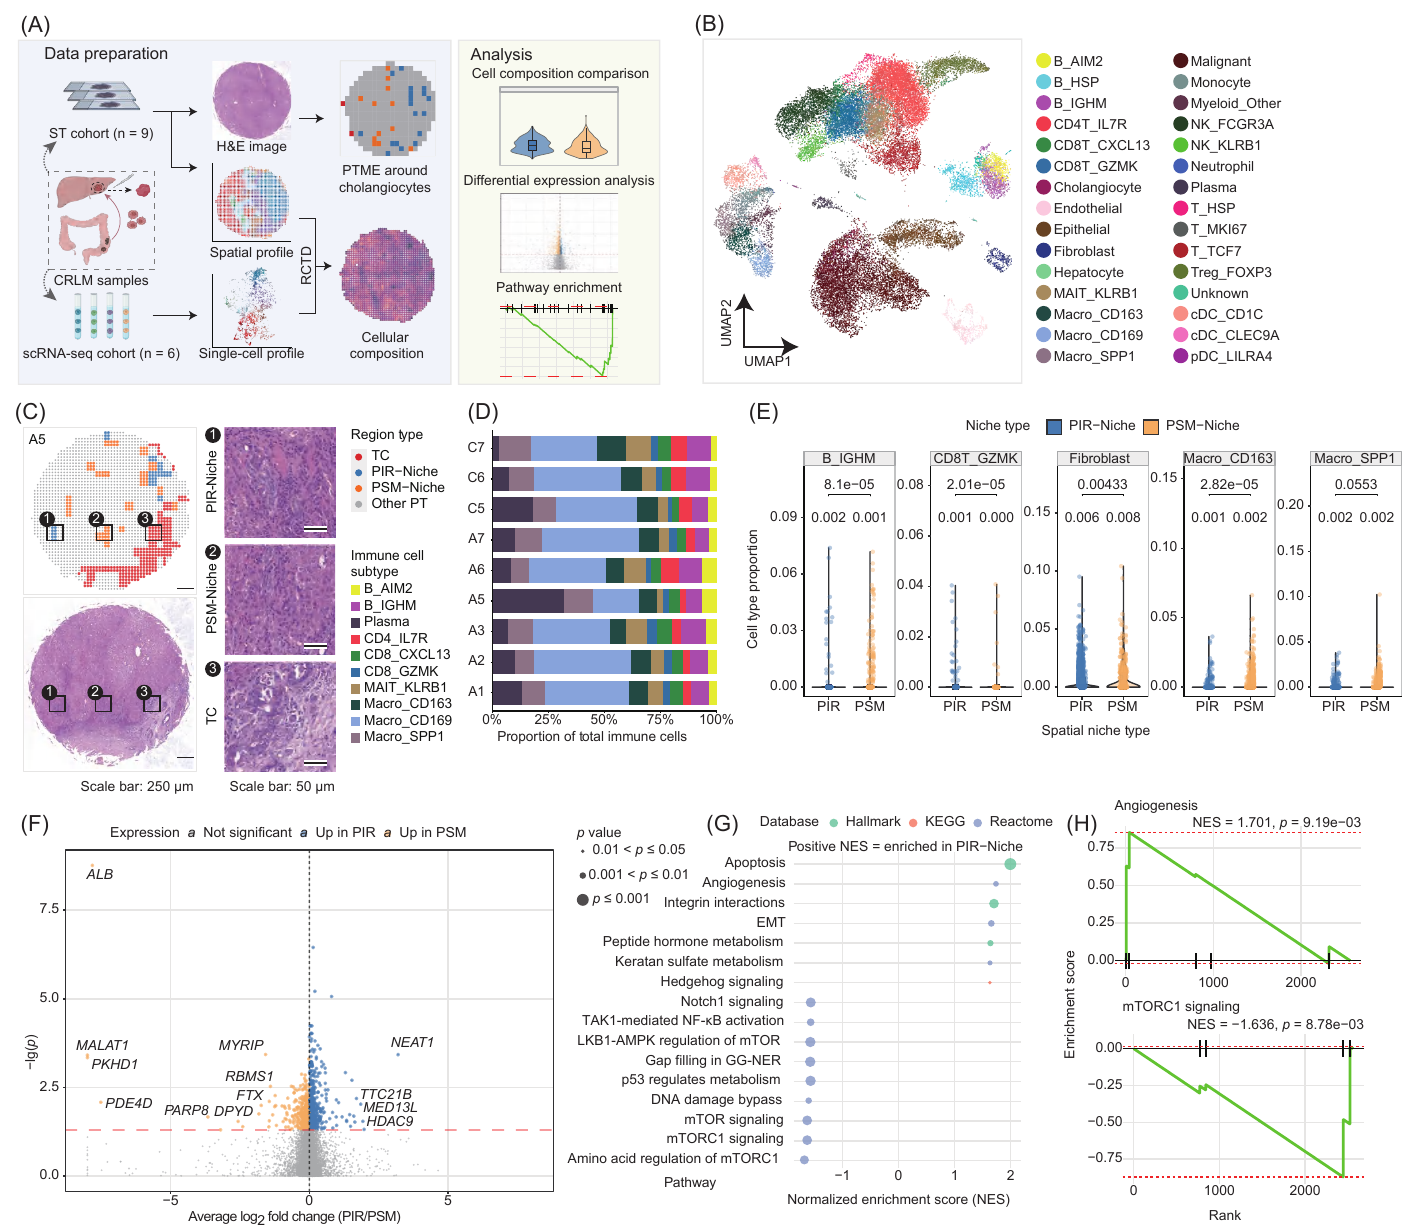

**Figure 7. Cross-modal transcriptomic characterization of molecular programs associated with PIR- and PSM-Niches.** (A) Workflow linking six scRNA-seq samples with nine spatial transcriptomics samples. (B) Reference UMAP colored by cell subtype. (C) Representative A5 niche map, matched H&E section and magnified PIR, PSM and tumor-core regions; scale bars, 250 μm in the overview and 50 μm in magnified views. (D) Immune subtype fractions across nine slides. (E) Spot-level RCTD proportions for B_IGHM, CD8T_GZMK, fibroblasts, Macro_CD163 and Macro_SPP1; blue denotes PIR and orange PSM, with nominal Wilcoxon P values and mean proportions. (F) Spot-level PIR/PSM differential expression: average log2 fold change versus −log10 nominal P; dot size indicates the P-value category. (G) Selected pathway NES values, with color identifying Hallmark, KEGG or Reactome. (H) Angiogenesis and mTORC1 signaling enrichment curves; titles report NES and nominal P.

[Download publication PDF](report_assets/figure7_publication.pdf).

## Saved Figure S15

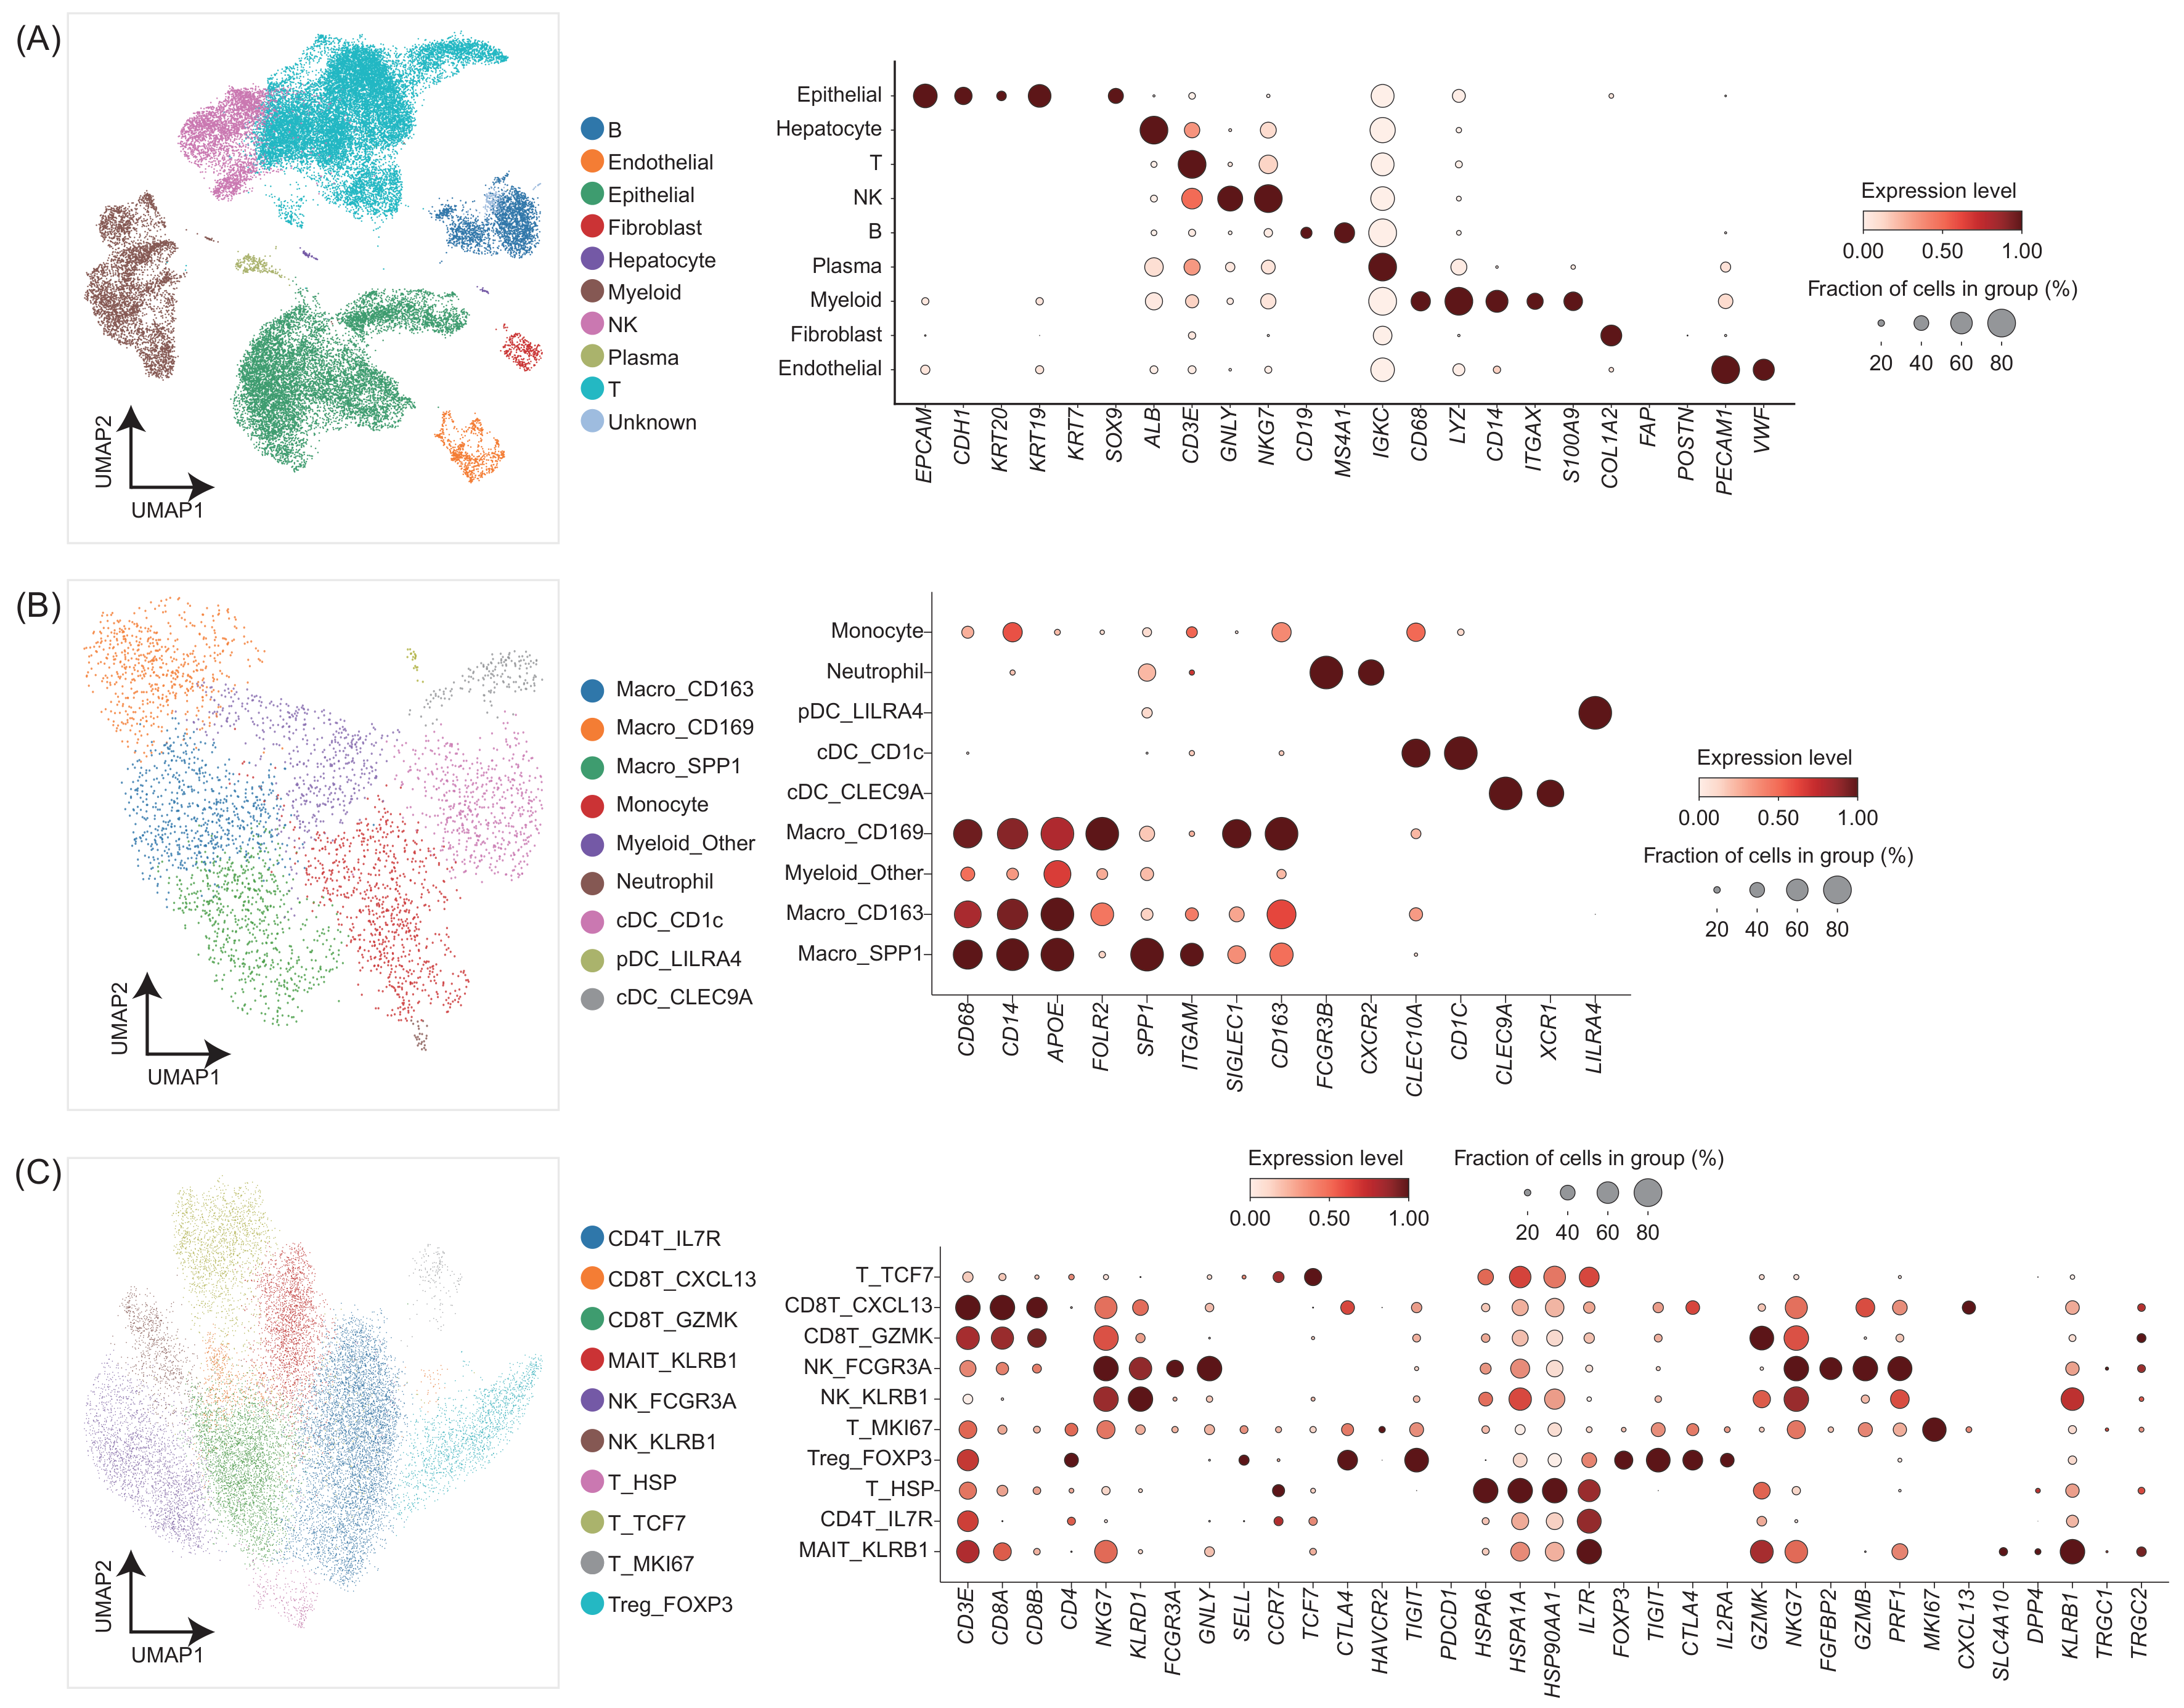

**Figure S15. Cell subpopulation annotation in single-cell transcriptomics data.** UMAPs and corresponding canonical-marker dot plots show major cell types (A), myeloid subpopulations (B), and T/NK subpopulations (C). Each UMAP point represents one cell. Dot size denotes the expressing-cell fraction and color denotes scaled expression.

## Relevant reading

- [Figure 7 workflow README](README.md): configuration, schemas and workflow order.
- [R Figure 7 report](Figure7.md): spatial stages and Figures S16–S18.
- Shared scRNA modules: [integration](../../src/scrna/integration.py), [annotation](../../src/scrna/annotation.py) and [R interoperability](../../src/scrna/interop.py).
- [Figure report guide](../../docs/rmd_display.md): saved figure displays and report organization.